# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name:** Aoun Ali
**Student ID:** 023-24-0074
**Section:** _(CS D)_
**GitHub:** _()_
**Kaggle:** _(add your Kaggle profile link)_
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

---

## Setup

In [1]:
import os, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

---

## 1. Problem Definition & Dataset Exploration

In [2]:
# Task 1 — load spam.csv, inspect shape/head/class balance
def balance(s):
    return pd.DataFrame({"count": s.value_counts(), "percent": (s.value_counts(normalize=True) * 100).round(2)})

spam_df = pd.read_csv("datasets/spam.csv", encoding="cp1252")[["v1", "v2"]]   # other 3 columns are empty overflow
spam_df.columns = ["label", "text"]

print("SPAM rows:", spam_df.shape[0])
print(spam_df.head())
print(balance(spam_df["label"]))

SPAM rows: 5572
  label                                               text
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
       count  percent
label                
ham     4825    86.59
spam     747    13.41


In [3]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
tweets_df = pd.read_csv("datasets/Tweets.csv")

print("TWEETS rows:", tweets_df.shape[0])
print(tweets_df[["airline", "airline_sentiment", "text"]].head())
print(balance(tweets_df["airline_sentiment"]))

n_before = len(tweets_df)
tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].reset_index(drop=True)
print(f"\nDropped {n_before - len(tweets_df)} neutral rows -> {len(tweets_df)} rows remain")
print(balance(tweets_df["airline_sentiment"]))

TWEETS rows: 14640
          airline airline_sentiment  \
0  Virgin America           neutral   
1  Virgin America          positive   
2  Virgin America           neutral   
3  Virgin America          negative   
4  Virgin America          negative   

                                                text  
0                @VirginAmerica What @dhepburn said.  
1  @VirginAmerica plus you've added commercials t...  
2  @VirginAmerica I didn't today... Must mean I n...  
3  @VirginAmerica it's really aggressive to blast...  
4  @VirginAmerica and it's a really big bad thing...  
                   count  percent
airline_sentiment                
negative            9178    62.69
neutral             3099    21.17
positive            2363    16.14

Dropped 3099 neutral rows -> 11541 rows remain
                   count  percent
airline_sentiment                
negative            9178    79.53
positive            2363    20.47


**Answer 1 (dataset summary):**

| Dataset | Rows | One row = | Target balance |
|---|---|---|---|
| Spam (`spam.csv`) | 5,572 | one SMS message + its label | ham 4,825 (86.59%), spam 747 (13.41%) |
| Tweets (`Tweets.csv`) | 14,640 | one tweet about a US airline + its sentiment label | negative 9,178 (62.69%), neutral 3,099 (21.17%), positive 2,363 (16.14%) |

After dropping neutral tweets, 3,099 rows are removed and **11,541 rows** remain: negative 9,178 (79.53%) and positive 2,363 (20.47%). Both targets are imbalanced, so accuracy alone is flattering and precision/recall matter.

**Answer 2 (Task A — spam):**
The practical problem is filtering unwanted or scam SMS so users are not flooded or defrauded, and the model decides whether a message goes to the inbox or the spam folder. Every message is either spam or ham, so it is a binary classification problem.

**Answer 2 (Task B — sentiment):**
The practical problem is helping an airline find unhappy passengers quickly, so complaints can be answered without reading every tweet. After dropping neutral tweets, each tweet is either positive or negative, which makes it binary.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

In [4]:
# Task 3 — clean text (lowercase + strip; the vectorizer handles tokenization and punctuation)
spam_df["text"] = spam_df["text"].str.lower().str.strip()
print(spam_df["text"].head(3).tolist())

['go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...', 'ok lar... joking wif u oni...', "free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's"]


In [5]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets
y = (spam_df["label"] == "spam").astype(int)      # ham = 0, spam = 1
X = spam_df["text"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

vec = CountVectorizer()
Xtr = vec.fit_transform(X_train)    # fit on TRAIN only
Xte = vec.transform(X_test)         # transform only

print("Train/test sizes:", Xtr.shape[0], Xte.shape[0])
print("Vocabulary size:", len(vec.vocabulary_))

Train/test sizes: 4457 1115
Vocabulary size: 7702


**Answer 4 (why fit on training data only):**
The test set has to behave like unseen, future messages. If the vectorizer were fit on all the data, test-set words (and, with TF-IDF, the IDF statistics) would leak into training and the test score would be over-optimistic. Fitting on train only means words that appear only in the test set are ignored, exactly as in deployment. The vocabulary has 7,702 words.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

Accuracy     0.9839
Precision    0.9645
Recall       0.9128
F1-score     0.9379
dtype: float64
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



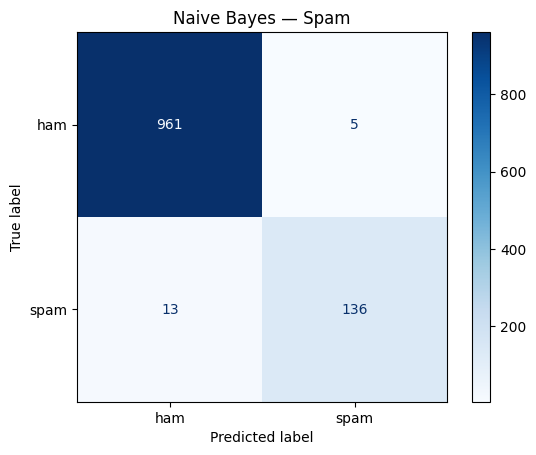

In [6]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1-score": f1_score(y_true, y_pred)}

nb = MultinomialNB().fit(Xtr, y_train)
pred = nb.predict(Xte)
res_nb_a = evaluate(y_test, pred)
print(pd.Series(res_nb_a).round(4))
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"], cmap="Blues")
plt.title("Naive Bayes — Spam"); plt.show()

**Task 5 — Spam Model Metrics** (spam = positive class; 1,115 test messages)

| Metric | Value |
|---|---|
| Accuracy | 0.9839 |
| Precision | 0.9645 |
| Recall | 0.9128 |
| F1-score | 0.9379 |

**Observation:** the confusion matrix shows 5 false positives (ham flagged as spam) and 13 false negatives (spam that got through). Always predicting ham already scores 86.6% accuracy, so precision and recall on the spam class are the more honest numbers.

**Answer 6:**
A false positive is worse here. A legitimate message (a bank alert, an OTP, a note from family) gets hidden from the user and can cause real harm, whereas a false negative is just one more spam text the user can ignore. So I would prioritize **precision** on the spam class. If tuning further I would raise the decision threshold, accepting some lost recall. Precision (0.9645) is currently higher than recall (0.9128), but 5 real messages were still flagged wrongly.

---

## 4. Task A: Word Interpretation (Spam)

In [7]:
# Task 7 — top spam words and top ham words from feature_log_prob_
words = vec.get_feature_names_out()

# Ranking by raw log P(w|class) just lists common words ("to", "call", "you") for BOTH classes,
# so rank by the log-ratio log P(w|spam) - log P(w|ham) instead.
raw_top_spam = words[np.argsort(nb.feature_log_prob_[1])[::-1][:8]]
print("Raw top spam words (not useful):", list(raw_top_spam))

score = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
order = np.argsort(score)
print("\nTop 15 SPAM words:", list(words[order[::-1][:15]]))
print("Top 15 HAM words: ", list(words[order[:15]]))

Raw top spam words (not useful): ['to', 'call', 'you', 'your', 'free', 'the', 'for', 'now']

Top 15 SPAM words: ['claim', 'prize', '150p', 'tone', '18', 'cs', 'guaranteed', '500', '1000', 'uk', '150ppm', 'awarded', 'www', 'collection', 'ringtone']
Top 15 HAM words:  ['gt', 'lt', 'he', 'da', 'lor', 'she', 'later', 'ì_', 'll', 'doing', 'say', 'really', 'ask', 'home', 'amp']


**Answer 7:**
Spam words: *claim, prize, awarded, guaranteed, tone, ringtone, 150p, 150ppm, 18, 500, 1000, uk, www, cs, collection*. These are prizes, premium-rate pricing, age limits, cash amounts and URLs, which matches my intuition. Ham words are casual chat: *he, she, later, doing, say, really, ask, home, ll, da, lor*. Two surprises: **gt, lt, amp** rank as strongly ham because they are HTML-escaped leftovers of `>`, `<` and `&` in friends' texts (dataset artifacts, not language), and *ì_* is a character-encoding artifact. My first attempt ranked by raw per-class probability and returned only stop words like "to", "call", "you" for both classes, which is why I switched to the log-ratio.

In [8]:
# Task 8 — test your own messages (same vectorizer and model as above)
my_messages = [
    "Hey, are we meeting for lunch today?",
    "Congratulations! You have won a free cash prize. Claim now!",
    "Can you call me when you get home?",
    "Your OTP is 482913. Do not share it with anyone.",
]
probs = nb.predict_proba(vec.transform([m.lower().strip() for m in my_messages]))[:, 1]
for m, p in zip(my_messages, probs):
    print(f"{'SPAM' if p > 0.5 else 'HAM ':4}  P(spam)={p:.3f}  {m}")

HAM   P(spam)=0.000  Hey, are we meeting for lunch today?
SPAM  P(spam)=1.000  Congratulations! You have won a free cash prize. Claim now!
HAM   P(spam)=0.000  Can you call me when you get home?
HAM   P(spam)=0.000  Your OTP is 482913. Do not share it with anyone.


**Answer 8:**
All four predictions matched what I expected. The prize message was predicted spam and the lunch message, the "call me when you get home" message and the OTP message were all predicted ham. The third message contains "call", a word common in spam, but it was still ham because the other words outweighed that single cue. The OTP message is a legitimate type of text, so ham is the right outcome, though it shows the model keys on vocabulary and could be fooled by a scam written in an OTP style. The probabilities are essentially exactly 0 or 1, because NB multiplies word likelihoods as if they were independent, which makes it overconfident even when it is right.

---

## 5. Task A: Kaggle Notebook Submission

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

In [9]:
# Task 11 — clean and vectorize the sentiment data
def clean_tweet(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)    # links
    t = re.sub(r"@\w+", " ", t)                # @mentions (airline handles)
    t = t.replace("&amp;", " and ")            # HTML leftover
    t = re.sub(r"[^a-z\s]", " ", t)            # '#', digits, punctuation, emojis
    return re.sub(r"\s+", " ", t).strip()

tweets_df["clean"] = tweets_df["text"].map(clean_tweet)
yb = (tweets_df["airline_sentiment"] == "negative").astype(int)   # negative = 1 (the class the airline wants to catch)

Xtr_b_txt, Xte_b_txt, ytr_b, yte_b = train_test_split(
    tweets_df["clean"], yb, test_size=0.2, random_state=42, stratify=yb)

vec_b = CountVectorizer(stop_words="english", min_df=2)
Xtr_b = vec_b.fit_transform(Xtr_b_txt)    # fit on TRAIN only
Xte_b = vec_b.transform(Xte_b_txt)
print("Train/test sizes:", Xtr_b.shape[0], Xte_b.shape[0], "| Vocabulary size:", len(vec_b.vocabulary_))
print(tweets_df[["text", "clean"]].head(3).to_string())

Train/test sizes: 9232 2309 | Vocabulary size: 4113
                                                                                                                             text                                                                                                       clean
0                                                        @VirginAmerica plus you've added commercials to the experience... tacky.                                                       plus you ve added commercials to the experience tacky
1  @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse  it s really aggressive to blast obnoxious entertainment in your guests faces and they have little recourse
2                                                                         @VirginAmerica and it's a really big bad thing about it                                                                    and it s a really big bad thing about

**Answer 12:**
Beyond lowercasing I removed URLs and @mentions, because every tweet starts with an airline handle, which is metadata rather than sentiment and only adds noise. I also removed punctuation, digits, emojis and HTML leftovers like `&amp;`, which are common in tweets and would become junk tokens. Because tweets are short and noisy I also dropped English stop words and words seen in fewer than 2 training tweets (`min_df=2`).

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

Accuracy     0.9194
Precision    0.9407
Recall       0.9592
F1-score     0.9498
dtype: float64
              precision    recall  f1-score   support

    positive       0.83      0.77      0.80       473
    negative       0.94      0.96      0.95      1836

    accuracy                           0.92      2309
   macro avg       0.88      0.86      0.87      2309
weighted avg       0.92      0.92      0.92      2309



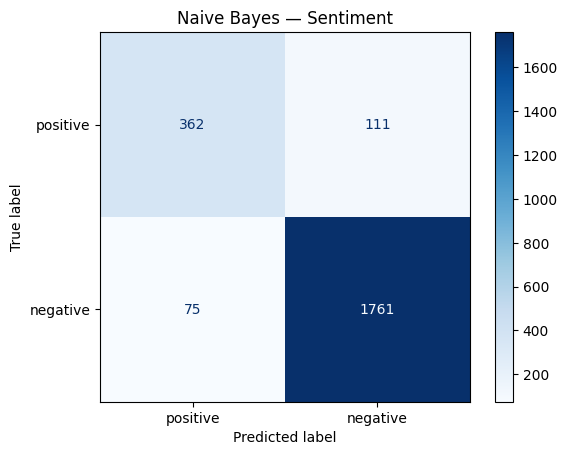

F1 on the minority class (positive tweets): 0.7956


In [10]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix (negative = class 1)
nb_b = MultinomialNB().fit(Xtr_b, ytr_b)
pred_b = nb_b.predict(Xte_b)
res_nb_b = evaluate(yte_b, pred_b)
print(pd.Series(res_nb_b).round(4))
print(classification_report(yte_b, pred_b, target_names=["positive", "negative"]))

ConfusionMatrixDisplay.from_predictions(yte_b, pred_b, display_labels=["positive", "negative"], cmap="Blues")
plt.title("Naive Bayes — Sentiment"); plt.show()

# Minority-class (positive tweets) view, for a fair comparison with Task A's minority class
pos_f1 = f1_score(yte_b, pred_b, pos_label=0)
print("F1 on the minority class (positive tweets):", round(pos_f1, 4))

**Task 13 — Sentiment Model Metrics** (negative = class 1; 2,309 test tweets)

| Metric | Value |
|---|---|
| Accuracy | 0.9194 |
| Precision | 0.9407 |
| Recall | 0.9592 |
| F1-score | 0.9498 |

**Answer 14:**
Naive Bayes did worse on sentiment than on spam in the way that matters. Accuracy dropped from 0.984 to 0.919, and the headline F1 of 0.950 is misleading because I scored the *majority* class (negative, 79.5% of tweets) as positive. On the minority class (positive tweets) F1 is only 0.80, with recall 0.77, versus 0.938 for the minority spam class. The independence assumption is much less reasonable for tweets: sentiment depends on negation and context ("not good", "thanks for nothing"), so words are strongly dependent and a bag of independent words misses it. Spam is signalled by individually strong keywords (*claim, prize, 150p*) whose evidence really does add up, and the 79.5/20.5 prior also pulls predictions toward negative.

---

## 8. Task B: Kaggle Notebook Submission

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

**Task 17 — Task A vs. Task B (Naive Bayes)**

In [11]:
# Task 17 — compare Naive Bayes on Task A vs. Task B
comp = pd.DataFrame({"Task A (Spam)": res_nb_a, "Task B (Sentiment)": res_nb_b}).round(4)
print(comp)
print("\nMinority-class F1 -> spam:", round(f1_score(y_test, pred), 4), "| positive tweets:", round(pos_f1, 4))

           Task A (Spam)  Task B (Sentiment)
Accuracy          0.9839              0.9194
Precision         0.9645              0.9407
Recall            0.9128              0.9592
F1-score          0.9379              0.9498

Minority-class F1 -> spam: 0.9379 | positive tweets: 0.7956


| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9839 | 0.9194 |
| Precision | 0.9645 | 0.9407 |
| Recall | 0.9128 | 0.9592 |
| F1-score | 0.9379 | 0.9498 |

Note: Task B's precision, recall and F1 are for the majority class (negative), so they look better than Task A's. Minority-class F1 is 0.938 for spam versus 0.80 for positive tweets.

In [12]:
# Task 18 — train Logistic Regression on Task A's vectorized features
lr = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
pred_lr = lr.predict(Xte)
res_lr_a = evaluate(y_test, pred_lr)
print(pd.DataFrame({"Naive Bayes": res_nb_a, "Logistic Regression": res_lr_a}).round(4))
print("NB confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred))
print("LR confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred_lr))

           Naive Bayes  Logistic Regression
Accuracy        0.9839               0.9812
Precision       0.9645               0.9923
Recall          0.9128               0.8658
F1-score        0.9379               0.9247
NB confusion matrix [[TN FP] [FN TP]]:
 [[961   5]
 [ 13 136]]
LR confusion matrix [[TN FP] [FN TP]]:
 [[965   1]
 [ 20 129]]


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 0.9839 | 0.9812 |
| Precision | 0.9645 | 0.9923 |
| Recall | 0.9128 | 0.8658 |
| F1-score | 0.9379 | 0.9247 |

**Answer 18 (which wins, and does it match expectations):**
It depends on the metric. Naive Bayes wins on accuracy, recall and F1, while Logistic Regression wins on precision (1 false positive versus 5, but 20 false negatives versus 13). I expected Logistic Regression to match or beat NB because it learns word weights jointly without the independence assumption, so this only partly matches. The gap is small (a few messages out of 1,115), and NB is known to be very competitive on small, sparse text data. Since I argued precision matters most for spam, Logistic Regression is arguably the better choice here.

---

## 10. Final Reflection & Conclusion

**Answer 19 — Conclusion:**
Naive Bayes suited the spam task better: it scored 0.984 accuracy and 0.938 F1 on the spam class, while on sentiment the positive-tweet class reached only 0.80 F1. Spam is identified by strong keyword cues whose evidence adds up roughly independently, whereas sentiment depends on negation and context. What surprised me about the top words was how much of the spam signal is pricing, age and URL patterns (*150p, 18, 1000, www*) rather than obvious words like "free", and that *gt, lt, amp* ranked as strongly ham because they are HTML-escape artifacts. Against Logistic Regression, NB was nearly tied, with slightly higher recall and F1, but Logistic Regression had much higher precision (0.992 versus 0.965), which matters most for spam filtering. One limitation of the independence assumption I observed is that NB's probabilities were almost exactly 0 or 1 on my own test messages, because it multiplies word likelihoods as if they were unrelated. A caveat is that 403 SMS texts are exact duplicates, so some may appear in both train and test and slightly inflate the Task A scores.

**Answer 20 — Kaggle Notebook Links:**
- Task A: _(paste link)_
- Task B: _(paste link)_

---

## Submission Checklist

- [x] Student-info block (add section, GitHub and Kaggle links)
- [x] Section 1 — Problem Definition & Dataset Exploration
- [x] Section 2 — Task A Cleaning & Vectorization
- [x] Section 3 — Task A Model & Evaluation
- [x] Section 4 — Task A Word Interpretation
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [x] Section 6 — Task B Cleaning & Vectorization
- [x] Section 7 — Task B Model & Evaluation
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [x] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [x] Section 10 — Final Reflection & Conclusion (add both Kaggle links)